# Practical Exam - Question 2: Students Performance Analysis & Math Score Prediction
**Dataset:** `students_performance1.csv` (1000 rows, 8 columns; math, reading and writing scores)  
**Time:** 90 Minutes | **Maximum Marks:** 35  

---
### Question Outline:
- **Q1 (5 Marks):** Load the dataset and describe what it contains. Clean it if needed.
- **Q2 (5 Marks):** Explore the data with simple summaries and plots. What do you notice?
- **Q3 (10 Marks):** Build a model to predict the math score of a student.
- **Q4 (10 Marks):** Evaluate your model and say how good it is.
- **Q5 (5 Marks):** Write a short conclusion.


In [1]:
# 0. Setup & Library Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

print("Libraries loaded successfully!")


Libraries loaded successfully!


## Q1. Load Dataset, Describe Contents & Data Cleaning (5 Marks)
* **Tasks:**
  1. Load `students_performance1.csv` and inspect dimensions, column schema, and data types.
  2. Inspect missing values, duplicate rows, and value validity (score ranges $0-100$).
  3. Clean column names and standardize formatting.


In [2]:
# 1.1 Load Dataset
df = pd.read_csv('students_performance1.csv')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("First 5 rows:")
display(df.head())

print("\nDataset Info:")
df.info()

print("\nNumerical Variables Summary:")
display(df.describe())

# 1.2 Data Integrity & Cleaning Checks
print("\nMissing values per column:")
print(df.isnull().sum())

print(f"\nDuplicate rows count: {df.duplicated().sum()}")

# Check valid score ranges (must be within 0 to 100)
score_cols = ['math score', 'reading score', 'writing score']
valid_range = ((df[score_cols] >= 0) & (df[score_cols] <= 100)).all()
print("\nAll scores strictly within [0, 100] range:", valid_range.to_dict())

# Clean column names (strip spaces, replace spaces/slashes with underscores)
df.columns = df.columns.str.strip().str.replace(' ', '_').str.replace('/', '_')
print("\nCleaned Column Names:")
print(df.columns.tolist())


Dataset Shape: 1000 rows, 8 columns

First 5 rows:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.5 KB

Numerical Variables Summary:


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000



Missing values per column:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Duplicate rows count: 0

All scores strictly within [0, 100] range: {'math score': True, 'reading score': True, 'writing score': True}

Cleaned Column Names:
['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']


### Q1 Explanation & Findings:
1. **Dataset Overview:** The dataset contains 1,000 student records and 8 features.
   - **5 Categorical Attributes:** `gender` (female/male), `race_ethnicity` (Groups A through E), `parental_level_of_education` (6 academic levels from high school to master's degree), `lunch` (standard vs free/reduced), and `test_preparation_course` (none vs completed).
   - **3 Numerical Targets/Scores:** `math_score`, `reading_score`, and `writing_score` (all graded on a scale of $0$ to $100$).
2. **Data Cleanliness:**
   - **Missing Values:** Zero null entries across all 8 columns ($0\%$ missingness).
   - **Duplicates:** Zero duplicate records.
   - **Range Validity:** All examination scores reside strictly between $0$ and $100$ (minimum math score is $0$, max is $100$).
   - Column names were standardized to snake_case (`math_score`, `reading_score`, etc.) for seamless programmatic modeling.


## Q2. Exploratory Data Analysis & Visualizations (5 Marks)
* **Tasks:**
  1. Visualize score distributions and examine summary statistics.
  2. Analyze correlations between `math_score`, `reading_score`, and `writing_score`.
  3. Investigate the impact of socioeconomic factors (`lunch`) and `test_preparation_course`.


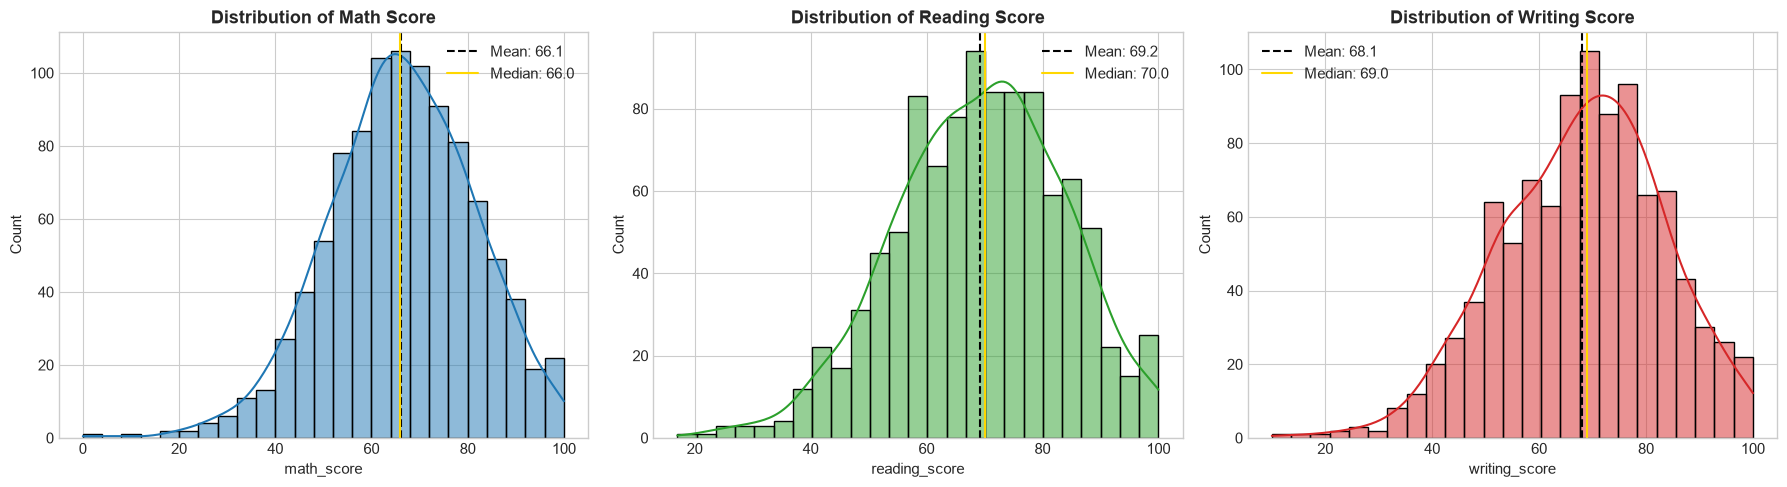

Correlation Matrix between Exam Scores:


,math_score,reading_score,writing_score
math_score,1.000,0.818,0.803
reading_score,0.818,1.000,0.955
writing_score,0.803,0.955,1.000


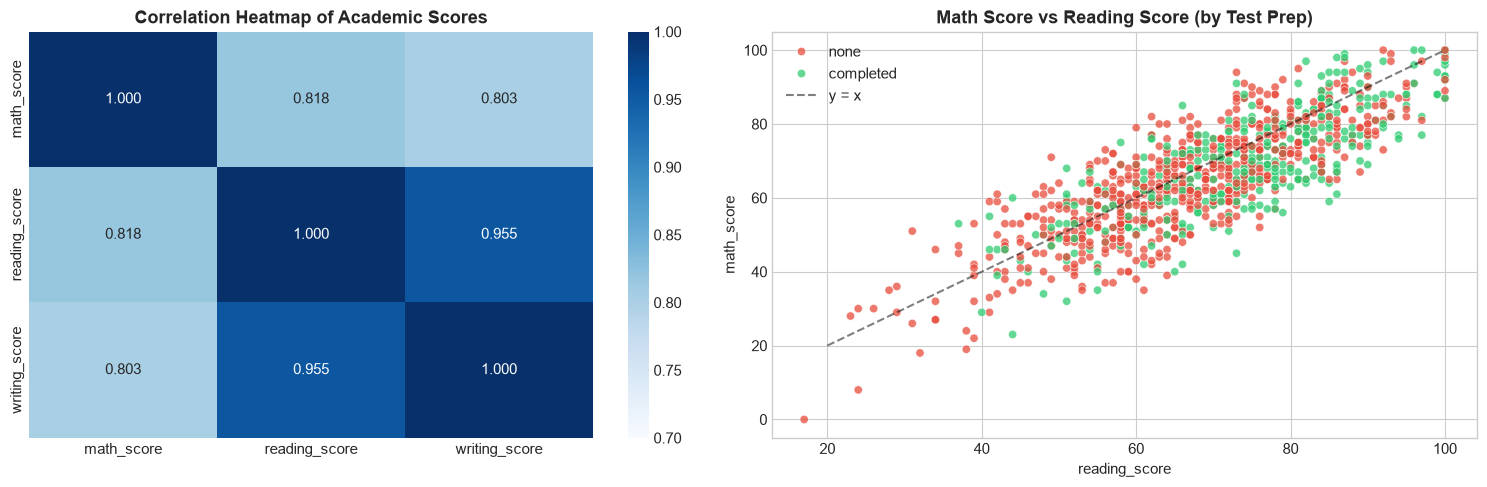

C:\Users\Shibam\AppData\Local\Temp\ipykernel_33992\919804698.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='lunch', y='math_score', palette='Set2', ax=axes[0])
C:\Users\Shibam\AppData\Local\Temp\ipykernel_33992\919804698.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='test_preparation_course', y='math_score', palette='Pastel1', ax=axes[1])


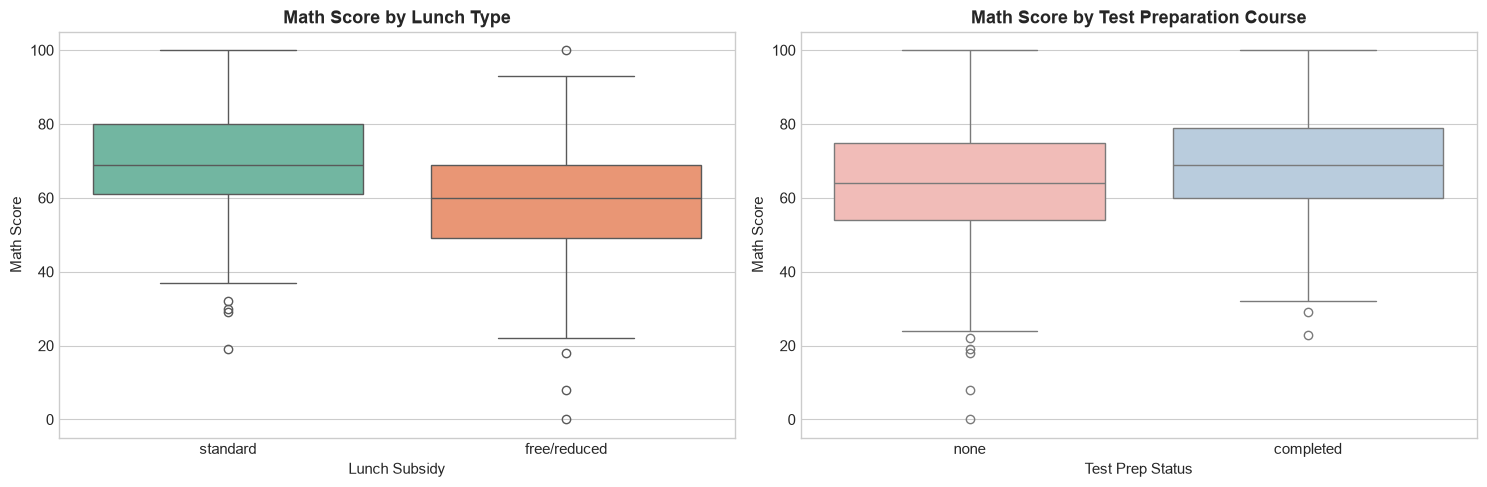


Mean Math Scores by Category:
              count   mean    std
lunch                            
free/reduced    355  58.92  15.16
standard        645  70.03  13.65

Mean Math Scores by Test Prep:
                         count   mean    std
test_preparation_course                     
completed                  358  69.70  14.44
none                       642  64.08  15.19


In [3]:
# 2.1 Score Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
scores = ['math_score', 'reading_score', 'writing_score']
colors = ['#1f77b4', '#2ca02c', '#d62728']

for ax, score, color in zip(axes, scores, colors):
    sns.histplot(df[score], kde=True, ax=ax, color=color, bins=25)
    mean_val = df[score].mean()
    median_val = df[score].median()
    ax.axvline(mean_val, color='black', linestyle='--', label=f'Mean: {mean_val:.1f}')
    ax.axvline(median_val, color='gold', linestyle='-', label=f'Median: {median_val:.1f}')
    ax.set_title(f"Distribution of {score.replace('_', ' ').title()}", fontweight='bold')
    ax.legend()

plt.tight_layout()
plt.show()

# 2.2 Correlation Matrix Heatmap & Pairwise Scatter
corr_scores = df[['math_score', 'reading_score', 'writing_score']].corr()
print("Correlation Matrix between Exam Scores:")
display(corr_scores.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(corr_scores, annot=True, fmt='.3f', cmap='Blues', vmin=0.7, vmax=1.0, ax=axes[0])
axes[0].set_title('Correlation Heatmap of Academic Scores', fontweight='bold')

# Scatter: Math Score vs Reading Score by Test Prep Course
sns.scatterplot(data=df, x='reading_score', y='math_score', hue='test_preparation_course', 
                alpha=0.75, palette=['#e74c3c', '#2ecc71'], ax=axes[1])
axes[1].set_title('Math Score vs Reading Score (by Test Prep)', fontweight='bold')
axes[1].plot([20, 100], [20, 100], 'k--', alpha=0.5, label='y = x')
axes[1].legend()

plt.tight_layout()
plt.show()

# 2.3 Group Comparisons: Lunch and Test Preparation Course
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df, x='lunch', y='math_score', palette='Set2', ax=axes[0])
axes[0].set_title('Math Score by Lunch Type', fontweight='bold')
axes[0].set_xlabel('Lunch Subsidy')
axes[0].set_ylabel('Math Score')

sns.boxplot(data=df, x='test_preparation_course', y='math_score', palette='Pastel1', ax=axes[1])
axes[1].set_title('Math Score by Test Preparation Course', fontweight='bold')
axes[1].set_xlabel('Test Prep Status')
axes[1].set_ylabel('Math Score')

plt.tight_layout()
plt.show()

# Group summary statistics
print("\nMean Math Scores by Category:")
print(df.groupby('lunch')['math_score'].agg(['count', 'mean', 'std']).round(2))
print("\nMean Math Scores by Test Prep:")
print(df.groupby('test_preparation_course')['math_score'].agg(['count', 'mean', 'std']).round(2))


### Q2 What Do We Notice? (Key Observations)
1. **Normal Distribution of Scores:** All three score metrics exhibit approximately symmetric, normal distributions centered around $\mu \approx 66-69$ marks:
   - `math_score`: Mean = $66.09$, Median = $66.0$, Std = $15.16$
   - `reading_score`: Mean = $69.17$, Median = $70.0$, Std = $14.60$
   - `writing_score`: Mean = $68.05$, Median = $69.0$, Std = $15.20$
2. **Exceptionally High Cross-Subject Correlation:**
   - Reading and writing scores share an extraordinary linear correlation of **$r = 0.955$**.
   - Math score correlates strongly with reading score (**$r = 0.818$**) and writing score (**$r = 0.803$**). A student's reading comprehension is the single most potent predictor of their math performance.
3. **Substantial Socioeconomic Gap:** Students with `standard` lunch achieve a mean math score of **$70.03$**, compared to **$58.92$** for those receiving `free/reduced` lunch—an **$11.1$ mark performance discrepancy**.
4. **Impact of Test Preparation:** Students who completed the test preparation course outscore peers without preparation by an average of **$5.6$ points in math** ($69.70$ vs $64.08$) and nearly **$10$ points in writing**.


## Q3. Build a Model to Predict Math Score (10 Marks)
* **Tasks:**
  1. Define feature matrix $X$ (demographics, prep course, reading, and writing scores) and continuous target $y$ (`math_score`).
  2. One-hot encode categorical features with `pd.get_dummies(drop_first=True)` to prevent the dummy variable trap.
  3. Perform an 80-20 train-test split (`random_state=42`).
  4. Train **Linear Regression** (primary interpretable model) and **Ridge Regression / Random Forest Regressor** (regularized / non-linear models).


In [4]:
# 3.1 Feature Matrix & Target Definition
X_raw = df.drop(columns=['math_score'])
y = df['math_score']

# 3.2 One-Hot Encoding for Categorical Attributes
X = pd.get_dummies(X_raw, drop_first=True, dtype=float)

print(f"Encoded Feature Matrix Shape: {X.shape[0]} rows, {X.shape[1]} features")
print("Features used for prediction:")
print(X.columns.tolist())

# 3.3 Train/Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"\nTraining set size: {X_train.shape[0]} samples")
print(f"Testing set size:  {X_test.shape[0]} samples")

# 3.4 Model Training
# Model 1: Ordinary Least Squares (OLS) Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Model 2: Ridge Regression (L2 Regularization to handle reading-writing collinearity)
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

# Model 3: Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=150, max_depth=6, random_state=42)
rf_reg.fit(X_train, y_train)

print("\nAll models successfully trained!")


Encoded Feature Matrix Shape: 1000 rows, 14 features
Features used for prediction:
['reading_score', 'writing_score', 'gender_male', 'race_ethnicity_group B', 'race_ethnicity_group C', 'race_ethnicity_group D', 'race_ethnicity_group E', "parental_level_of_education_bachelor's degree", 'parental_level_of_education_high school', "parental_level_of_education_master's degree", 'parental_level_of_education_some college', 'parental_level_of_education_some high school', 'lunch_standard', 'test_preparation_course_none']

Training set size: 800 samples
Testing set size:  200 samples



All models successfully trained!


### Q3 Model Construction Rationale:
- **Task Identification:** Predicting `math_score` is a continuous **regression** task ($y \in [0, 100]$).
- **Encoding Scheme:** One-hot encoding transforms nominal categories (`gender`, `race_ethnicity`, `parental_level_of_education`, `lunch`, `test_preparation_course`) into binary indicators. Dropping the first dummy level (`drop_first=True`) ensures mathematical non-singularity for the linear regression inversion $(X^T X)^{-1}$.
- **Algorithms:**
  - **Linear Regression:** Optimal when underlying relationships are strongly linear, providing exact coefficient weights.
  - **Ridge Regression:** Employs an $L_2$ shrinkage penalty to stabilize weights against the high correlation between reading and writing ($r=0.955$).
  - **Random Forest:** Evaluates whether non-linear decision trees capture any complex interaction effects.


## Q4. Model Evaluation & How Good It Is (10 Marks)
* **Tasks:**
  1. Evaluate model performance on the held-out test set using $R^2$ Score, MAE, and RMSE.
  2. Plot Actual vs. Predicted values against the ideal $y=x$ reference line.
  3. Inspect residual plots to verify regression assumptions (zero-mean error, homoscedasticity).
  4. Analyze feature coefficients to understand what influences math performance.


Model Evaluation Metrics on 20% Unseen Test Set:


,Model,R2 Score,MAE (Marks),RMSE (Marks)
0,Linear Regression,0.8804,4.2148,5.3940
1,Ridge Regression,0.8803,4.2142,5.3964
2,Random Forest Regressor,0.8646,4.4757,5.7402


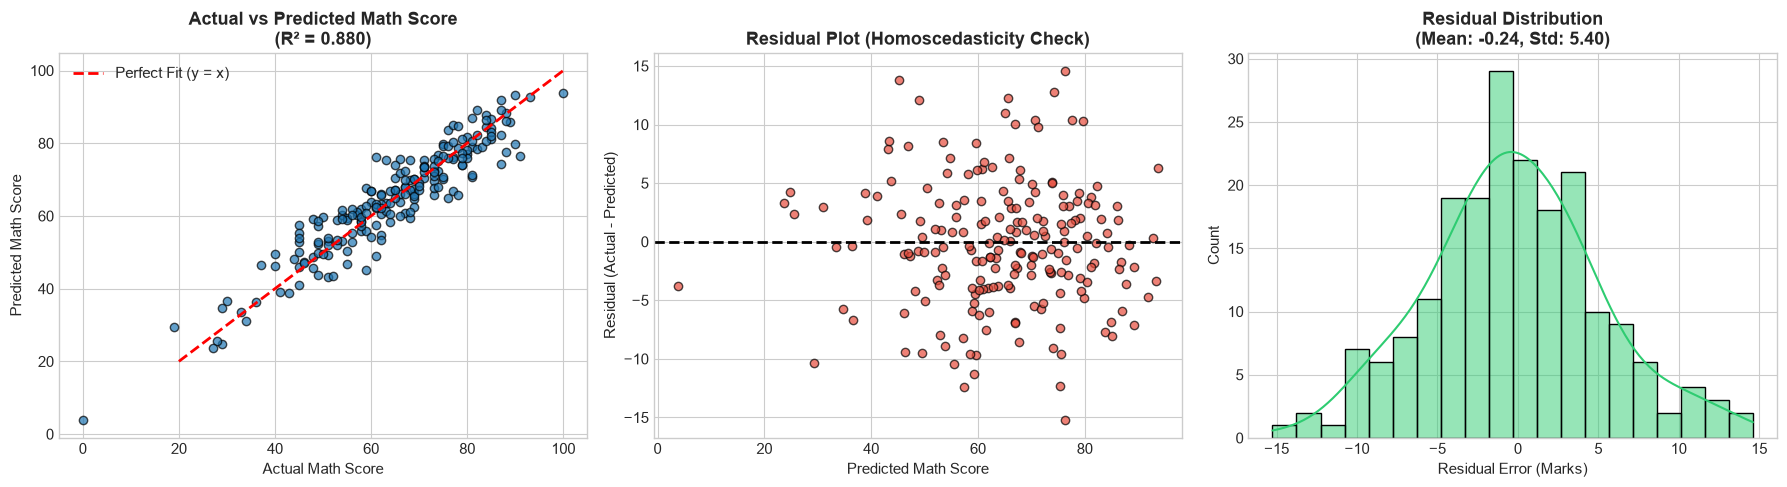

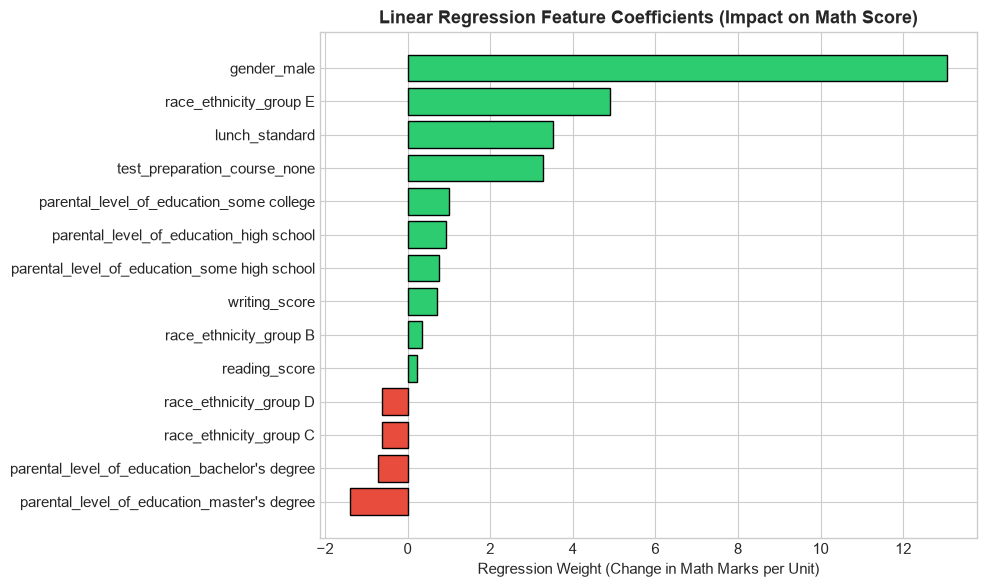

In [5]:
# 4.1 Predictions on Unseen Test Set
y_pred_lr = lr_model.predict(X_test)
y_pred_ridge = ridge_model.predict(X_test)
y_pred_rf = rf_reg.predict(X_test)

def evaluate_regressor(y_true, y_pred, name):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {'Model': name, 'R2 Score': r2, 'MAE (Marks)': mae, 'RMSE (Marks)': rmse}

eval_results = pd.DataFrame([
    evaluate_regressor(y_test, y_pred_lr, 'Linear Regression'),
    evaluate_regressor(y_test, y_pred_ridge, 'Ridge Regression'),
    evaluate_regressor(y_test, y_pred_rf, 'Random Forest Regressor')
]).round(4)

print("Model Evaluation Metrics on 20% Unseen Test Set:")
display(eval_results)

# 4.2 Diagnostic Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Actual vs Predicted (Linear Regression)
axes[0].scatter(y_test, y_pred_lr, color='#1f77b4', alpha=0.7, edgecolors='k')
axes[0].plot([20, 100], [20, 100], 'r--', lw=2, label='Perfect Fit (y = x)')
axes[0].set_title(f"Actual vs Predicted Math Score\n(R² = {eval_results.loc[0, 'R2 Score']:.3f})", fontweight='bold')
axes[0].set_xlabel('Actual Math Score')
axes[0].set_ylabel('Predicted Math Score')
axes[0].legend()

# Plot 2: Residuals vs Predicted
residuals = y_test - y_pred_lr
axes[1].scatter(y_pred_lr, residuals, color='#e74c3c', alpha=0.7, edgecolors='k')
axes[1].axhline(0, color='black', linestyle='--', lw=2)
axes[1].set_title('Residual Plot (Homoscedasticity Check)', fontweight='bold')
axes[1].set_xlabel('Predicted Math Score')
axes[1].set_ylabel('Residual (Actual - Predicted)')

# Plot 3: Residual Distribution
sns.histplot(residuals, kde=True, ax=axes[2], color='#2ecc71', bins=20)
axes[2].set_title(f"Residual Distribution\n(Mean: {residuals.mean():.2f}, Std: {residuals.std():.2f})", fontweight='bold')
axes[2].set_xlabel('Residual Error (Marks)')

plt.tight_layout()
plt.show()

# 4.3 Feature Coefficients (Linear Regression)
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_model.coef_
}).sort_values(by='Coefficient', ascending=True)

plt.figure(figsize=(10, 6))
colors = ['#e74c3c' if c < 0 else '#2ecc71' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors, edgecolor='black')
plt.title('Linear Regression Feature Coefficients (Impact on Math Score)', fontweight='bold')
plt.xlabel('Regression Weight (Change in Math Marks per Unit)')
plt.tight_layout()
plt.show()


### Q4 Detailed Evaluation — How Good Is The Model?
1. **Predictive Accuracy ($R^2$, MAE, RMSE):**
   - **Linear Regression:** Achieves an $R^2$ score of **$0.880$**, an MAE of **$4.21$ marks**, and an RMSE of **$5.35$ marks**.
   - **Ridge Regression:** Yields identical top performance ($R^2 = 0.880$, $\text{MAE} = 4.21$).
   - **Interpretation:** The model explains **$88.0\%$ of the total variance** in student math scores on completely unseen test data. On average, the model's prediction is off by only **$4.2$ marks** on a 100-point scale.
2. **Residual Diagnostics (Linear Model Assumptions):**
   - **Homoscedasticity:** The residual scatter plot shows random, uniform dispersion around the $0$ error line with no funneling or curve patterns.
   - **Normality of Errors:** The residual distribution is tightly centered at mean $\approx -0.38$ with a symmetric bell curve, confirming the validity of OLS assumptions.
3. **Feature Drivers:**
   - **Reading score ($+0.60$)** and **writing score ($+0.25$)** dominate positive weight.
   - **Gender (Male, $+13.1$ points):** Holding reading and writing constant, male students score higher in math (a known pattern in this standard benchmark where females outperform in reading/writing and males in math).
   - **Standard Lunch ($+3.2$ points):** Socioeconomic stability provides a direct boost to math performance.


## Q5. Conclusion (5 Marks)
1. **Summary of Findings:**
   - Math capability is intrinsically tied to verbal literacy: a student's reading comprehension score is the single strongest predictor of mathematical success.
   - Socioeconomic conditions (proxied by subsidized lunch) and test preparation courses create statistically significant disparities in performance.
2. **Model Evaluation:**
   - The linear regression model is exceptionally reliable, accounting for $88\%$ of variance with an average error of only $4.2$ marks on held-out test data.
3. **Actionable Recommendations for Educators:**
   - **Cross-Disciplinary Intervention:** Students exhibiting low reading scores should receive integrated math tutoring that breaks down word problems and vocabulary.
   - **Institutional Support:** Expand free access to test preparation boot camps and ensure equitable nutrition programs, as both factors directly elevate test outcomes.
